# Point2MAE — reconstruct a LAS point cloud

Load a **`best.pt` or `last.pt` produced by `Point2MAE_training.ipynb`** and a
LAS/LAZ input, inspect original and predicted geometry side by side, then save
predicted points as a new LAS file. Select the **Point-M2AE (CUDA 12.4)** kernel.
Keep `point2mae_reconstruction.py` and `point2mae_grouping.py` beside this notebook.

The model reconstructs **masked local patches of its middle-level hierarchy**.
It is not a dense point-for-point decoder: the output count differs from the
input, neighbourhoods overlap, and some geometry may be missing. Multiple
masking passes cover more patches; we retain the first prediction for each
patch. No original points are added to make the result appear complete.
Patch coverage is reported below and is not a raw-point coverage metric.
The upstream masking implementation always exposes middle-level centre zero,
so full patch coverage is not expected even with many passes.

The checkpoint supplies grouping, XY positional embeddings, and preprocessing.
Centroid-only and older XY-radius preprocessing are both inverted for export.
Fixed-count checkpoints and classifier/encoder-only weights are not supported.
This notebook performs inference only and does not start training.

## 1. Set the model and LAS paths

Edit the three paths below. Leave `OUTPUT_LAS` empty to create a unique result
under `reconstructions/`. An existing output file or the input file cannot be
overwritten. Increase `NUM_PASSES` for more patch coverage at additional runtime.
`MAX_PLOT_POINTS` only limits display points; every predicted point is exported.

In [10]:
from pathlib import Path
from datetime import datetime, timezone
import sys
import uuid

WORKSPACE = Path('/home/khan365/Point-M2AE-main').resolve()
MODEL_ROOT = WORKSPACE / 'Point-M2AE-main'

MODEL_PATH = '/home/khan365/Point-M2AE-main/training_runs/pointm2ae_xy_20261030T190853Z_d323ddc4/best.pt'   # e.g. /.../training_runs/pointm2ae_xy_.../best.pt
INPUT_LAS = '/home/khan365/Point-M2AE-main/Output/full_20261006_001322_611477/LS_head_scarp_Slope_units/UTU/SU_9044.las'    # e.g. /.../All_Slope_Units/LAM_1/SU_123.las
OUTPUT_LAS = 'Reconstruction_las/output2.las'   # Optional full output path ending in .las

NUM_PASSES = 1
SEED = 42
CUDA_DEVICE = 0
MAX_PLOT_POINTS = 100000

if not MODEL_PATH.strip() or not INPUT_LAS.strip():
    raise ValueError('Set MODEL_PATH and INPUT_LAS in this cell, then rerun from here.')
model_path = Path(MODEL_PATH).expanduser().resolve()
input_path = Path(INPUT_LAS).expanduser().resolve()
for path in (model_path, input_path):
    if not path.is_file():
        raise FileNotFoundError(path)
if input_path.suffix.lower() not in ('.las', '.laz'):
    raise ValueError('INPUT_LAS must be a LAS or LAZ file.')
if not OUTPUT_LAS.strip():
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    output_path = WORKSPACE / 'reconstructions' / f'{input_path.stem}_{stamp}_{uuid.uuid4().hex[:8]}.las'
else:
    output_path = Path(OUTPUT_LAS).expanduser().resolve()
if output_path == input_path or output_path.suffix.lower() != '.las':
    raise ValueError('Choose a different .las file for output.')
if output_path.exists():
    raise FileExistsError(f'Output already exists: {output_path}')
if type(NUM_PASSES) is not int or NUM_PASSES < 1:
    raise ValueError('NUM_PASSES must be a positive integer.')
if type(SEED) is not int or not 0 <= SEED < 2**32:
    raise ValueError('SEED must be an integer in [0, 2**32).')
if type(MAX_PLOT_POINTS) is not int or MAX_PLOT_POINTS < 1:
    raise ValueError('MAX_PLOT_POINTS must be a positive integer.')
sys.path.insert(0, str(WORKSPACE))
print('Checkpoint:', model_path)
print('Input:', input_path)
print('Output:', output_path)

Checkpoint: /home/khan365/Point-M2AE-main/training_runs/pointm2ae_xy_20261030T190853Z_d323ddc4/best.pt
Input: /home/khan365/Point-M2AE-main/Output/full_20261006_001322_611477/LS_head_scarp_Slope_units/UTU/SU_9044.las
Output: /home/khan365/Point-M2AE-main/Reconstruction_las/output2.las


## 2. Load the checkpoint and original cloud

All input points are retained. Preprocessing uses the configuration saved in
the checkpoint, not the current training-notebook defaults. The original XYZ
array remains in source coordinates for comparison and export.

In [11]:
import json
import numpy as np
import laspy
import torch
import matplotlib.pyplot as plt
from point2mae_reconstruction import (
    load_checkpoint_model, prepare_cloud, reconstruct_cloud,
    restore_coordinates, plot_comparison, save_reconstruction_las,
)

model, run_config, checkpoint_info = load_checkpoint_model(model_path, MODEL_ROOT, CUDA_DEVICE)
source_cloud = laspy.read(input_path)
original_xyz = np.asarray(source_cloud.xyz, dtype=np.float64)
model_points, cloud_centroid, cloud_scale = prepare_cloud(original_xyz, run_config['normalization'])
print('Checkpoint epoch:', checkpoint_info['epoch'])
print('Device:', torch.cuda.get_device_name(CUDA_DEVICE))
print('Preprocessing:', run_config['normalization'])
print('Input points:', len(original_xyz))
print('Cloud centroid:', cloud_centroid)
print('Cloud scale:', cloud_scale)
print('Group divisors:', run_config['model']['group_divisors'])

2026-10-30 19:40:10,281 - Point_M2AE - INFO - [Point_M2AE]


Checkpoint epoch: 5
Device: NVIDIA GeForce RTX 4080 Laptop GPU
Preprocessing: subtract cloud XYZ centroid only; no rescaling
Input points: 41862
Cloud centroid: [7.43482434e+05 2.02201642e+06 1.83938976e+02]
Cloud scale: 1.0
Group divisors: [8, 2, 4]


## 3. Reconstruct masked patches

`model.eval()` freezes dropout and BatchNorm statistics. Reconstruction still
uses masking (`eval=False` in the upstream forward call); `eval=True` would
return an embedding instead of predicted coordinates. The seed fixes the mask
sequence for repeatable comparisons. One full cloud must fit in GPU memory.
The code will not downsample the input if memory is insufficient.

In [12]:
model_reconstruction, report = reconstruct_cloud(model, model_points, passes=NUM_PASSES, seed=SEED)
reconstructed_xyz = restore_coordinates(model_reconstruction, cloud_centroid, cloud_scale)
print(f'Original points: {len(original_xyz):,}')
print(f'Predicted points: {len(reconstructed_xyz):,}')
print(f'Middle patches predicted: {report["covered_middle_patches"]:,} / '
      f'{report["total_middle_patches"]:,} ({report["patch_coverage_fraction"]:.1%})')
print('Mean masked-patch Chamfer loss (model-coordinate units squared):',
      report['mean_masked_chamfer_model_units'])
print('This is a masked-patch score, not a full-cloud reconstruction error.')

Original points: 41,862
Predicted points: 16,872
Middle patches predicted: 2,109 / 2,617 (80.6%)
Mean masked-patch Chamfer loss (model-coordinate units squared): 0.793951153755188
This is a masked-patch score, not a full-cloud reconstruction error.


## 4. Original and reconstructed side by side

Both panels use the same XYZ limits, aspect ratio, viewing angle, and elevation
colour scale. Axes display offsets from the **input** centroid for readability;
the exported LAS uses the original coordinate system. Sampling below affects
the plot only. Re-run this cell to change display settings without inference.

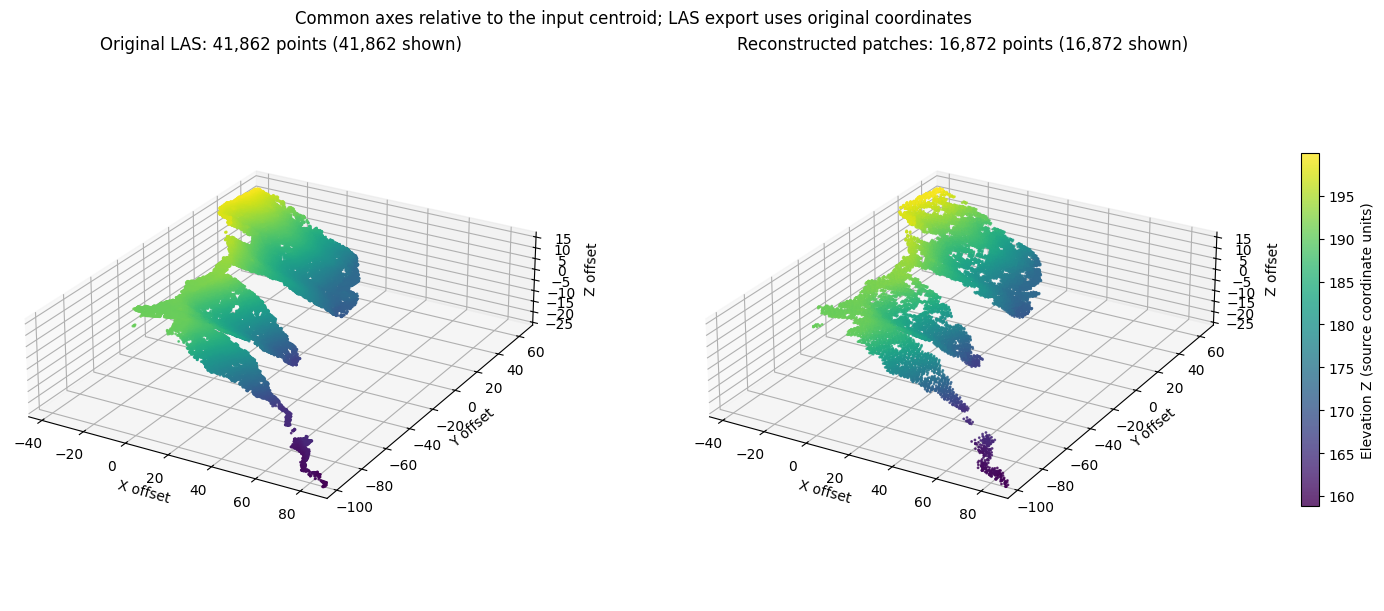

In [13]:
comparison_figure = plot_comparison(original_xyz, reconstructed_xyz, max_points=MAX_PLOT_POINTS, seed=SEED)
plt.show()

## 5. Save the reconstructed LAS

Run this cell to write all predicted XYZ points to `OUTPUT_LAS` (or the generated
path). It also saves the comparison PNG and a JSON report. LAS coordinate
scales, offsets, and CRS records come from the input; coordinates are quantized
to the source precision. Intensity, classification, returns and timestamps
are not predicted and use zero defaults. Original input data is not modified.

The LAS contains only predictions. It does not contain a mixture of visible
original points and predicted points. To create a second result, rerun the
settings cell with a new output path, then the following cells.

In [5]:
report_path = output_path.with_suffix('.json')
figure_path = output_path.with_suffix('.png')
for path in (output_path, report_path, figure_path):
    if path.exists():
        raise FileExistsError(f'Output already exists: {path}; choose a new output path.')

metadata = {
    **report, 'checkpoint': checkpoint_info, 'input_las': str(input_path),
    'output_las': str(output_path), 'normalization': run_config['normalization'],
    'group_divisors': run_config['model']['group_divisors'],
    'cloud_centroid': cloud_centroid.tolist(), 'cloud_scale': cloud_scale,
    'coordinate_scales': source_cloud.header.scales.tolist(),
    'coordinate_offsets': source_cloud.header.offsets.tolist(),
    'source_crs_records': sum(v.user_id == 'LASF_Projection' for v in source_cloud.header.vlrs)
                          + sum(v.user_id == 'LASF_Projection' for v in (source_cloud.header.evlrs or [])),
    'attributes': 'XYZ predictions; other LAS point attributes are zero defaults',
}
saved_path = save_reconstruction_las(output_path, reconstructed_xyz, source_cloud.header, input_path)
with report_path.open('x') as handle:
    json.dump(metadata, handle, indent=2, allow_nan=False)
with figure_path.open('xb') as handle:
    comparison_figure.savefig(handle, format='png', dpi=160)
with laspy.open(saved_path) as saved:
    assert saved.header.point_count == len(reconstructed_xyz)
print('Reconstruction LAS:', saved_path)
print('Comparison PNG:', figure_path)
print('Report JSON:', report_path)

Reconstruction LAS: /home/khan365/Point-M2AE-main/Reconstruction_las/output2.las
Comparison PNG: /home/khan365/Point-M2AE-main/Reconstruction_las/output2.png
Report JSON: /home/khan365/Point-M2AE-main/Reconstruction_las/output2.json
